# Simulación y análisis de opciones Call y Put

**Parámetros base:** $S_0 = 100$, $K = 100$, $r = 5\%$, $\sigma = 20\%$, $T = 1$, $M = 10{,}000$

$$S_T = S_0 \exp\left[\left(r - \tfrac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\,Z\right]$$

$$\text{Call} = e^{-rT}\,E[\max(S_T - K, 0)] \qquad \text{Put} = e^{-rT}\,E[\max(K - S_T, 0)]$$

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.rcParams['figure.figsize'] = (11, 5)


def bs_precios(S0, K, r, sigma, T):
    """Precio analítico Black-Scholes para call y put."""
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    call = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    put  = K*np.exp(-r*T)*norm.cdf(-d2) - S0*norm.cdf(-d1)
    return call, put


def mc_precios(S0, K, r, sigma, T, M=10_000, seed=42):
    """Precio Monte Carlo para call y put sobre la misma simulación."""
    np.random.seed(seed)
    Z  = np.random.normal(0, 1, M)
    ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
    
    call = np.exp(-r*T) * np.maximum(ST - K, 0).mean()
    put  = np.exp(-r*T) * np.maximum(K - ST, 0).mean()
    return call, put, ST

## Parte 1 - Simulación y comparación con Black-Scholes

In [26]:
S0, K, r, sigma, T, M = 100, 100, 0.05, 0.20, 1, 10_000

call_mc, put_mc, ST = mc_precios(S0, K, r, sigma, T, M)
call_bs, put_bs     = bs_precios(S0, K, r, sigma, T)

comparacion = pd.DataFrame({
    'Opción': ['Call', 'Put'],
    'Monte Carlo': [call_mc, put_mc],
    'Black-Scholes': [call_bs, put_bs],
    'Diferencia': [abs(call_mc - call_bs), abs(put_mc - put_bs)],
    'P(terminar ITM)': [(ST > K).mean(), (ST < K).mean()] # ITM = IN THE MONEY
})

print(comparacion.round(4).to_string(index=False))

Opción  Monte Carlo  Black-Scholes  Diferencia  P(terminar ITM)
  Call      10.4502        10.4506      0.0004           0.5583
   Put       5.6017         5.5735      0.0282           0.4417


In [27]:
# Verificación de paridad put-call

izquierda = call_mc - put_mc
derecha   = S0 - K*np.exp(-r*T)

print(f"C - P            : {izquierda:.4f}")
print(f"S₀ - K·e^(-rT)   : {derecha:.4f}")
print(f"Diferencia       : {abs(izquierda - derecha):.4f}")

C - P            : 4.8485
S₀ - K·e^(-rT)   : 4.8771
Diferencia       : 0.0286


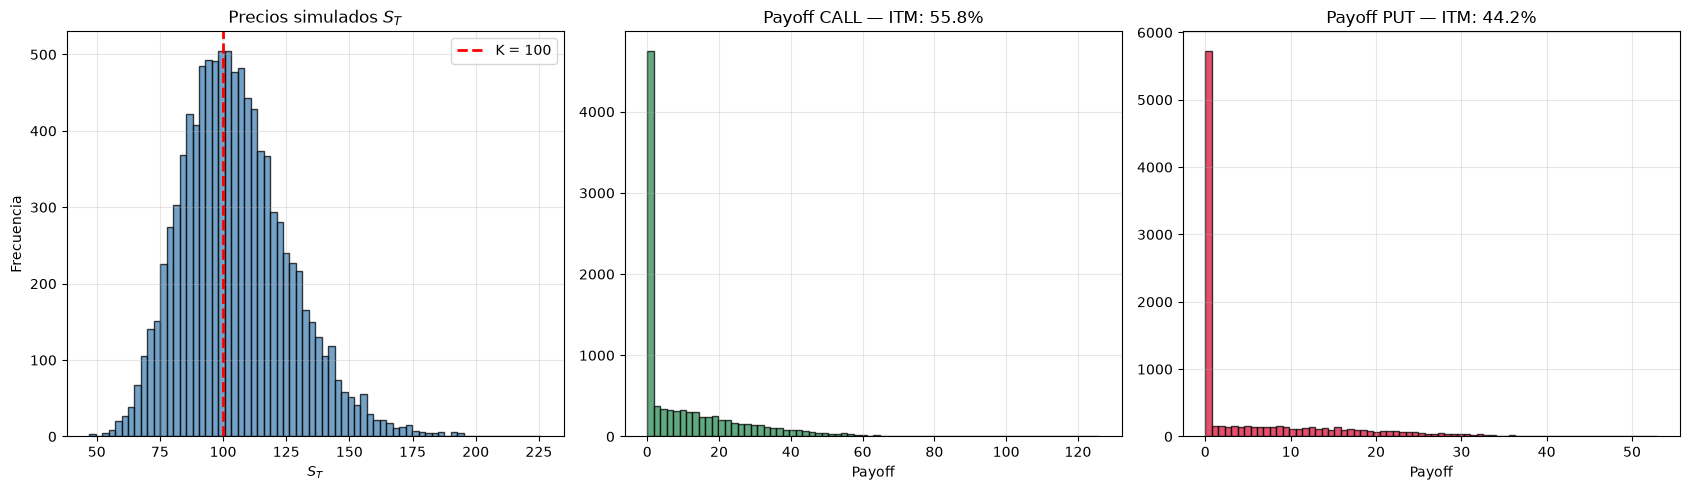

In [28]:
# Histogramas de payoffs

payoff_call = np.maximum(ST - K, 0)
payoff_put  = np.maximum(K - ST, 0)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].hist(ST, bins=70, color='steelblue', edgecolor='black', alpha=0.75)
axes[0].axvline(K, color='red', ls='--', lw=2, label=f'K = {K}')
axes[0].set_title('Precios simulados $S_T$')
axes[0].set_xlabel('$S_T$'); axes[0].set_ylabel('Frecuencia')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].hist(payoff_call, bins=70, color='seagreen', edgecolor='black', alpha=0.75)
axes[1].set_title(f'Payoff CALL — ITM: {(ST>K).mean():.1%}')
axes[1].set_xlabel('Payoff'); axes[1].grid(alpha=0.3)

axes[2].hist(payoff_put, bins=70, color='crimson', edgecolor='black', alpha=0.75)
axes[2].set_title(f'Payoff PUT — ITM: {(ST<K).mean():.1%}')
axes[2].set_xlabel('Payoff'); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Parte 2 y 3 - Sensibilidad y visualización

Se varía un parámetro a la vez manteniendo los demás en su valor base.


In [29]:
def analizar(parametro, valores, base=None):
    """Varía un parámetro y devuelve tabla + gráfica de call y put."""
    if base is None:
        base = dict(S0=100, K=100, r=0.05, sigma=0.20, T=1)
    
    filas = []
    for v in valores:
        p = base.copy()
        p[parametro] = v
        c, pu, _ = mc_precios(**p, M=10_000)
        c_bs, p_bs = bs_precios(**p)
        filas.append({parametro: v, 'Call MC': c, 'Put MC': pu,
                      'Call BS': c_bs, 'Put BS': p_bs})
    
    return pd.DataFrame(filas)


def graficar(tabla, parametro, etiqueta):
    plt.figure(figsize=(10, 5))
    plt.plot(tabla[parametro], tabla['Call MC'], marker='o', ms=8, lw=2.5,
             color='seagreen', label='Call')
    plt.plot(tabla[parametro], tabla['Put MC'], marker='s', ms=8, lw=2.5,
             color='crimson', label='Put')
    plt.xlabel(etiqueta); plt.ylabel('Precio de la opción')
    plt.title(f'Precio de la opción vs {etiqueta}')
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

 S0  Call MC  Put MC  Call BS  Put BS
 80   1.8795 17.0253   1.8594 16.9824
 90   5.0970 10.2456   5.0912 10.2142
100  10.4502  5.6017  10.4506  5.5735
110  17.6535  2.8079  17.6630  2.7859
120  26.1511  1.3084  26.1690  1.2920


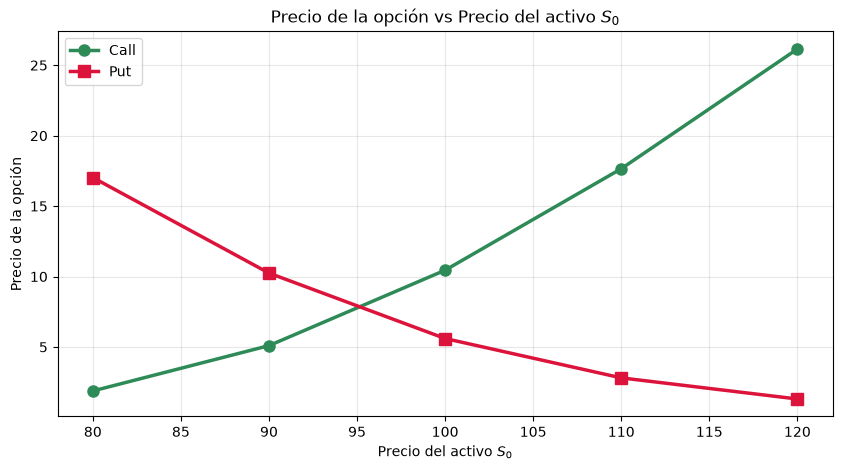

In [30]:
# PRECIO DEL ACTIVO S0

t_S0 = analizar('S0', [80, 90, 100, 110, 120])
print(t_S0.round(4).to_string(index=False))
graficar(t_S0, 'S0', 'Precio del activo $S_0$')

  K  Call MC  Put MC  Call BS  Put BS
 80  24.5731  0.7000  24.5888  0.6872
 90  16.6917  2.3310  16.6994  2.3101
100  10.4502  5.6017  10.4506  5.5735
110   6.0447 10.7086   6.0401 10.6753
120   3.2703 17.4465   3.2475 17.3950


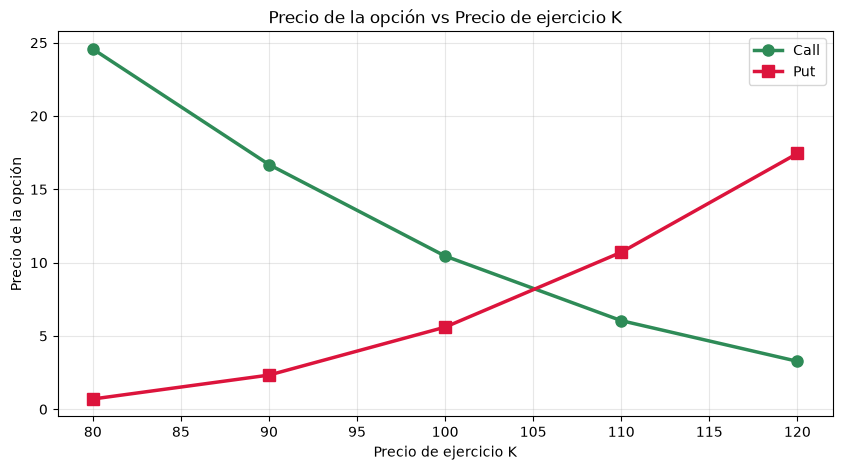

In [31]:
# STRIKE

t_K = analizar('K', [80, 90, 100, 110, 120])
print(t_K.round(4).to_string(index=False))
graficar(t_K, 'K', 'Precio de ejercicio K')

 sigma  Call MC  Put MC  Call BS  Put BS
   0.1   6.8004  1.9412   6.8050  1.9279
   0.2  10.4502  5.6017  10.4506  5.5735
   0.3  14.2369  9.3914  14.2313  9.3542
   0.4  18.0444 13.1932  18.0230 13.1459
   0.5  21.8357 16.9693  21.7926 16.9155


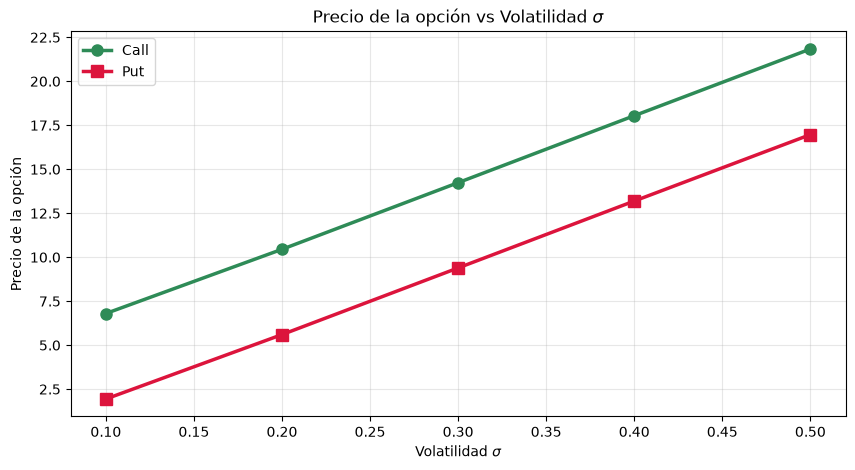

In [32]:
# VOLATILIDAD

t_sigma = analizar('sigma', [0.10, 0.20, 0.30, 0.40, 0.50])
print(t_sigma.round(4).to_string(index=False))
graficar(t_sigma, 'sigma', 'Volatilidad $\\sigma$')

   T  Call MC  Put MC  Call BS  Put BS
0.25   4.6133  3.3890   4.6150  3.3728
0.50   6.8874  4.4417   6.8887  4.4197
1.00  10.4502  5.6017  10.4506  5.5735
1.50  13.4430  6.2483  13.4429  6.2173
2.00  16.1279  6.6433  16.1268  6.6105


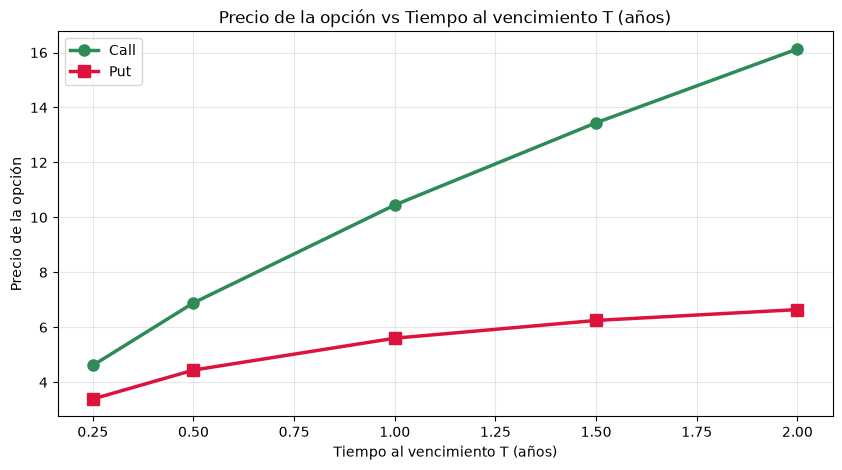

In [33]:
# TIEMPO

t_T = analizar('T', [0.25, 0.5, 1, 1.5, 2])
print(t_T.round(4).to_string(index=False))
graficar(t_T, 'T', 'Tiempo al vencimiento T (años)')

   r  Call MC  Put MC  Call BS  Put BS
0.05  10.4502  5.6017  10.4506  5.5735
0.10  13.2649  3.7772  13.2697  3.7534
0.15  16.3478  2.4472  16.3560  2.4268
0.20  19.6170  1.5187  19.6299  1.5030


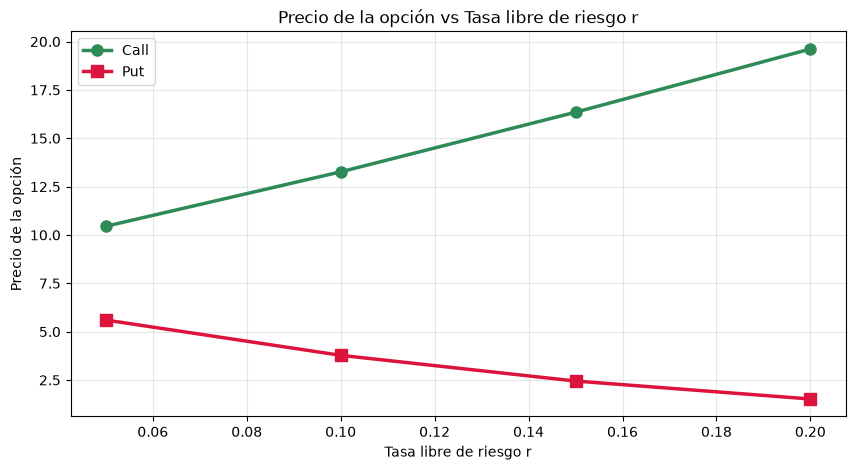

In [34]:
# TASA LIBRE DE RIESGO r

t_r = analizar('r', [0.05, 0.10, 0.15, 0.20])
print(t_r.round(4).to_string(index=False))
graficar(t_r, 'r', 'Tasa libre de riesgo r')

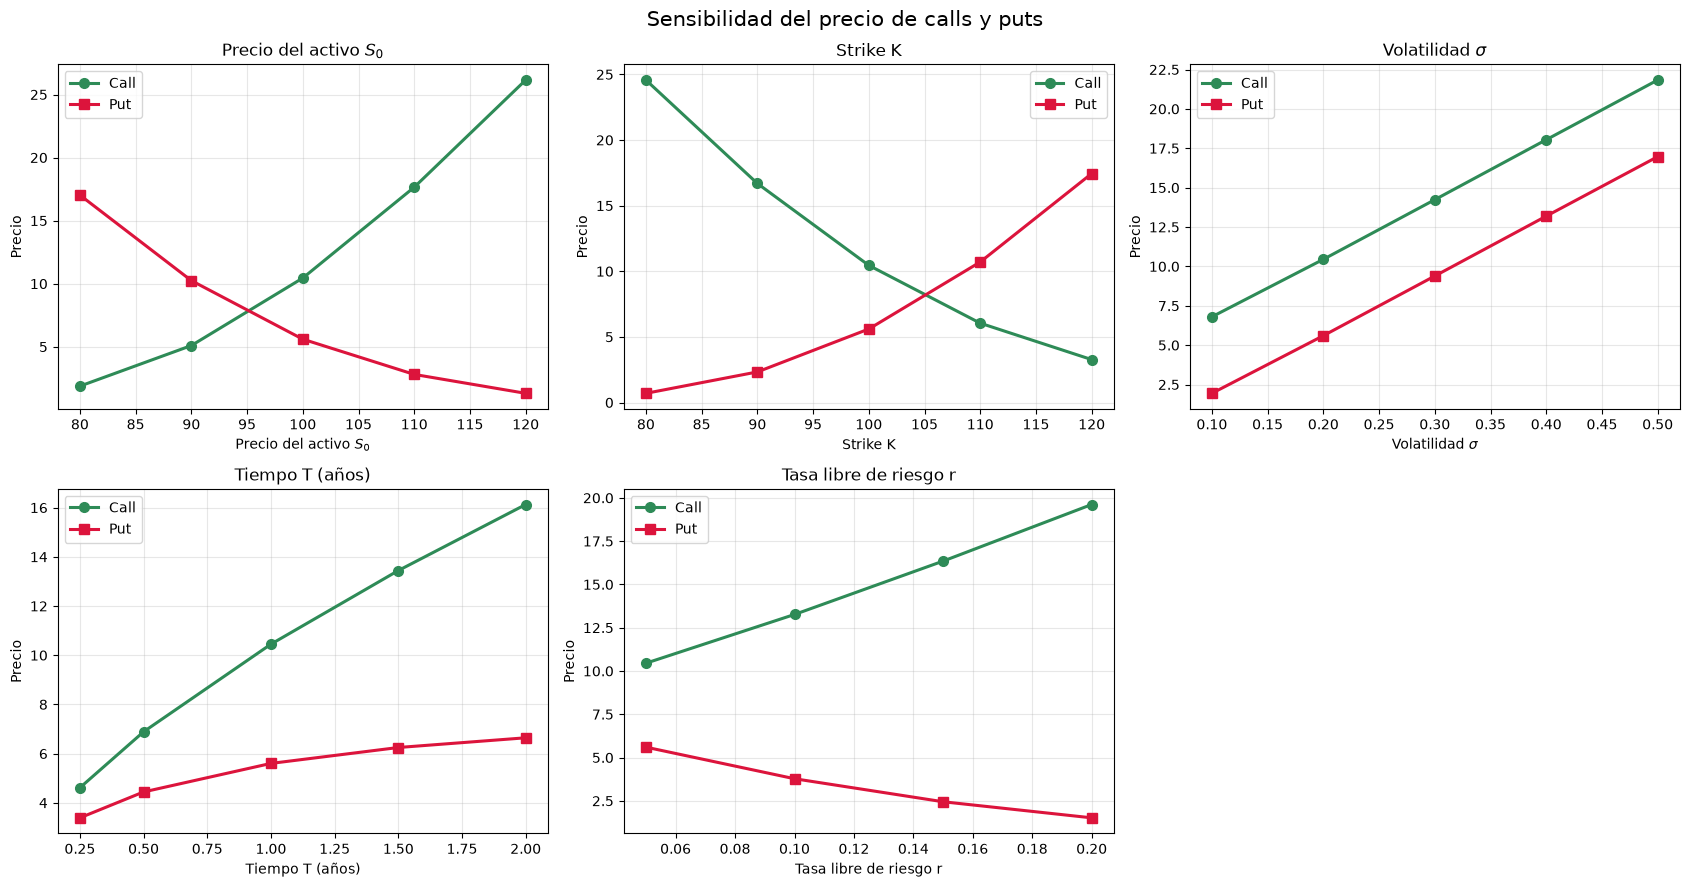

In [35]:
# RESUMEN

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

datos = [
    (t_S0,    'S0',    'Precio del activo $S_0$',   axes[0,0]),
    (t_K,     'K',     'Strike K',                  axes[0,1]),
    (t_sigma, 'sigma', 'Volatilidad $\\sigma$',     axes[0,2]),
    (t_T,     'T',     'Tiempo T (años)',           axes[1,0]),
    (t_r,     'r',     'Tasa libre de riesgo r',    axes[1,1]),
]

for tabla, param, etiq, ax in datos:
    ax.plot(tabla[param], tabla['Call MC'], marker='o', ms=7, lw=2.2,
            color='seagreen', label='Call')
    ax.plot(tabla[param], tabla['Put MC'], marker='s', ms=7, lw=2.2,
            color='crimson', label='Put')
    ax.set_xlabel(etiq); ax.set_ylabel('Precio')
    ax.set_title(etiq)
    ax.legend(); ax.grid(alpha=0.3)

axes[1,2].axis('off')
plt.suptitle('Sensibilidad del precio de calls y puts', fontsize=15)
plt.tight_layout()
plt.show()

## Parte 4 - Interpretación

### Precio del activo

**¿Por qué la call aumenta cuando sube el precio de la acción?**

La call paga $\max(S_T - K, 0)$: el activo entra sumando. Al subir $S_0$ toda
la distribución de $S_T$ se desplaza hacia la derecha, así que más escenarios
superan el strike y los que ya lo superaban lo hacen por más margen. El precio
pasa de 1.88 a 26.15 cuando $S_0$ va de 80 a 120.

**¿Por qué la put se comporta distinto?**

La put paga $\max(K - S_T, 0)$: el activo entra restando. El mismo
desplazamiento hacia la derecha reduce su payoff, y el precio cae de 17.03 a
1.31. Son posiciones opuestas sobre el mismo evento — por eso sus curvas se
cruzan en las gráficas.

Formalmente, $\Delta_{call} > 0$ y $\Delta_{put} < 0$.

### Volatilidad

**¿Por qué mayor incertidumbre aumenta el valor?**

Aumenta el valor de **ambas** opciones: la call va de 6.80 a 21.84 y la put de
1.94 a 16.97 cuando $\sigma$ pasa de 10% a 50%.

La razón es la **asimetría del payoff**. Una opción trunca las pérdidas en cero:
comprar una call y que el precio caiga a 50 cuesta lo mismo que si cae a 90 —
en ambos casos pierdes solo la prima. Pero si sube a 200 en lugar de 120, ganas
mucho más.

Más volatilidad amplía tanto los escenarios buenos como los malos, pero solo los
buenos se traducen en ganancia. Es la única variable que mueve call y put en la
misma dirección ($\nu > 0$ para ambas).

### Tiempo

**¿Siempre es deseable tener más tiempo?**

Para el **comprador**, más tiempo casi siempre es mejor: más oportunidad de que
el precio se mueva a su favor, con la pérdida acotada a la prima. La call sube
de 4.61 a 16.13 al pasar de 0.25 a 2 años.

Para el **vendedor** es lo contrario. Cobra la prima al inicio y su riesgo es la
pérdida potencial: cuanto más tiempo, más probable que el mercado se mueva en su
contra. El paso del tiempo lo beneficia ($\theta < 0$ para el comprador).

**Matiz importante:** el efecto no es lineal. La dispersión crece como
$\sqrt{T}$, así que una opción a 2 años no vale el doble que una a 1 año.

**Y en la put el efecto casi se agota:** de T=1 a T=2 apenas sube de 5.60 a 6.64.
Más tiempo aumenta la dispersión (favorable), pero también descuenta más el
strike que eventualmente recibiría (desfavorable). Las dos fuerzas se compensan.

### Strike

**¿Cómo modifica la probabilidad de terminar in-the-money?**

Un strike más alto **reduce** la probabilidad de que la call termine ITM y la
**aumenta** para la put. En las simulaciones, la probabilidad de la call cae de
89.6% con K=80 a 22.0% con K=120.

Además de la frecuencia cambia la magnitud: con strike más alto, incluso los
escenarios ganadores pagan menos, porque a cada payoff se le resta un $K$ mayor.
Ambos efectos empujan el precio de la call en la misma dirección.

**Definición de in-the-money:** una opción está ITM cuando tiene valor si se
ejerciera en ese momento — es decir, cuando su valor intrínseco es positivo.

| Estado | Call | Put |
|---|---|---|
| **ITM** (in the money) | $S > K$ | $S < K$ |
| **ATM** (at the money) | $S = K$ | $S = K$ |
| **OTM** (out of the money) | $S < K$ | $S > K$ |

El valor temporal es máximo en ATM, donde la incertidumbre sobre el resultado
final es mayor.

## Parte 5 - Comparación con el mercado

**¿Cuál parámetro es más importante monitorear?**

**La volatilidad**, por tres razones que se desprenden de los resultados.

**1. Es el único parámetro no observable.** $S_0$, $K$, $T$ y $r$ se leen
directamente del mercado. $\sigma$ hay que estimarla, y cualquier error en esa
estimación se traduce directo en un error de valuación. Es la única fuente
genuina de desacuerdo entre participantes.

**2. Su impacto es grande y afecta a ambas posiciones.** Al pasar de 10% a 50%
la call se triplica y la put se multiplica por casi 9. A diferencia de $S_0$ o
$K$, donde una posición gana y la otra pierde, aquí no hay cobertura natural
entre call y put: ambas se mueven juntas.

**3. Es el supuesto más frágil del modelo.** Black-Scholes asume $\sigma$
constante, pero la evidencia empírica muestra clustering de volatilidad, saltos
y colas más pesadas que la normal. El *volatility smile* demuestra que el
mercado no cree en ese supuesto: si lo creyera, la volatilidad implícita sería
idéntica para todos los strikes.

**Matiz según el rol:**

- Un **operador direccional** monitorea $S_0$: es lo que mueve su P&L día a día.
- Un **market maker** que se cubre en delta neutraliza $S_0$ y queda expuesto
  precisamente a $\sigma$ — su negocio *es* la volatilidad.
- En horizontes largos o para derivados de tasas, $r$ gana relevancia.

**Conclusión:** el precio del activo determina la ganancia inmediata, pero la
volatilidad determina cuánto vale la opción en primer lugar y es donde se
concentra el riesgo de modelo.